# 13 · Cold start: refreshed lists and new tokens (work package 5, core problem 3)

**Work package 5** of the [implementation plan](../../research/implementation_plan.md). Notebook 10 showed that
24% (Dev A) and 31% (Dev B) of the tokens accounts pick up did not exist when the list was made. Under the main
protocol, which makes one list at $t$ and judges it on the next two days, no model can reach them.

This notebook uses a **second protocol** (implementation plan, section 7.1): lists are rebuilt every $R$ hours
inside the two target days, and each pick-up is judged against the account's list from the last rebuild before
it. The baseline is rebuilt in the same way, so the comparison stays fair. With $R = 48$ hours this is exactly the
main protocol.

Models compared (code in `src/scripts/cold_start.py`):

| Model | What it lists |
| --- | --- |
| baseline, refreshed | the 10 most popular tokens of the 14 days before each rebuild |
| newest-popular | among tokens younger than $A$ hours, those with the most accounts so far: the trivial heuristic Schein et al. (2002) ask every cold-start study to report |
| time-weighted blend, refreshed | the model chosen in notebook 12 |
| mixed list | the time-weighted blend's best $10 - m$ tokens plus the $m$ best young tokens |

**Procedure.** $A$ and $m$ are chosen on Dev A with $R = 6$ hours; the chosen mixed list is reported on Dev B for
every refresh interval.

In [1]:
import json
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cold_start as cs
import plots
import protocol as pc
import stats
import token_data as td
import tuning

plots.style()
pd.set_option("display.float_format", "{:,.4f}".format)
OUT = pc.RESULTS_DIR / "wp5"
OUT.mkdir(parents=True, exist_ok=True)
CONFIGS = pc.RESULTS_DIR.parent / "configs"

legs = td.load_legs()
tokens = td.load_tokens()
blend_settings = json.loads((CONFIGS / "wp4_time.json").read_text())
blend_settings = {k: blend_settings[k] for k in ("k", "shrink", "weight", "half_life", "history_days")}
print("Time-weighted blend from notebook 12:", blend_settings)

Time-weighted blend from notebook 12: {'k': 400, 'shrink': 200.0, 'weight': 0.2, 'half_life': 7.0, 'history_days': None}


## 1. How soon after launch are new tokens picked up?

For every cold pair of the Dev A points: the age of the token, in hours, when the account first traded it. If most
pick-ups happen within hours of the launch, lists must be rebuilt within hours to reach them.

In [2]:
ages = []
for t in pc.POINTS["dev_a"]:
    task = pc.load_task(legs, t)
    pairs = cs.first_trades_in_target(legs, task)
    cold = pairs[pairs["cold"]]
    launch = cold["token"].map(tokens.set_index("token_id")["first_timestamp"])
    ages.append(((cold["first_time"] - launch).dt.total_seconds() / 3600).to_numpy())
ages = np.concatenate(ages)

share_within = pd.Series({f"within {h} h": (ages < h).mean() for h in (1, 3, 6, 12, 24, 48)})
print(f"{len(ages):,} cold pairs on Dev A. Share picked up within ... hours of the token's first trade:")
share_within.to_frame("share of cold pairs")

44,514 cold pairs on Dev A. Share picked up within ... hours of the token's first trade:


,share of cold pairs
within 1 h,0.7692
within 3 h,0.8424
within 6 h,0.8968
within 12 h,0.9507
within 24 h,0.9903
within 48 h,1.0000


## 2. Choosing $A$ and $m$ on Dev A (lists rebuilt every 6 hours)

All settings are scored in one pass over the rebuild times (`refreshed_evaluate`), and the time-weighted blend is
fitted once per rebuild and shared by every mixed list (`shared_across_models`).

In [3]:
AGES = [6, 24]  # A, hours
N_NEW = [1, 2, 3]  # m


def blend_factory(state, tokens):
    """The time-weighted blend of notebook 12, fitted on the history before the rebuild time."""
    return tuning.fixed_blend_scorer(state, blend_settings)


def models_for_tuning():
    base = cs.shared_across_models(blend_factory)
    models = {"baseline, refreshed": cs.popularity_factory, "time-weighted blend, refreshed": base}
    for a in AGES:
        models[f"newest-popular A={a}"] = cs.newest_popular_factory(a)
        for m in N_NEW:
            models[f"mixed A={a} m={m}"] = cs.mixed_factory(base, a, m)
    return models


TUNE_DIR = OUT / "tuning_dev_a"  # one file per point, so a stopped run resumes
TUNE_DIR.mkdir(exist_ok=True)


def tuning_for_point(t: pd.Timestamp) -> pd.DataFrame:
    """Every tuning model at one Dev A point with lists rebuilt every 6 hours, read from disk if already computed."""
    point_file = TUNE_DIR / f"{t:%Y-%m-%d}.csv"
    if point_file.exists():
        return pd.read_csv(point_file, parse_dates=["point"])
    task = pc.load_task(legs, t)
    results = cs.refreshed_evaluate(models_for_tuning(), legs, task, tokens, hours=6)
    table = pd.DataFrame([cs.summarize_refreshed(name, 6, task, per_user) for name, per_user in results.items()])
    table.to_csv(point_file, index=False)
    print(f"  {t:%d %b}: done", flush=True)
    return table


tuning_table = pd.concat([tuning_for_point(t) for t in pc.POINTS["dev_a"]], ignore_index=True)

summary = tuning_table.groupby("model")[["recall", "cold_reached"]].mean().sort_values("recall", ascending=False)
summary

,recall,cold_reached
model,,
"time-weighted blend, refreshed",0.2535,0.0741
mixed A=24 m=1,0.2505,0.0803
mixed A=6 m=1,0.2495,0.0807
mixed A=24 m=2,0.2450,0.0828
mixed A=6 m=2,0.2445,0.0857
mixed A=24 m=3,0.2384,0.0869
mixed A=6 m=3,0.2359,0.0854
"baseline, refreshed",0.0866,0.0000
newest-popular A=24,0.0471,0.0739


In [4]:
mixed = summary[summary.index.str.startswith("mixed")]
best_name = mixed["recall"].idxmax()
chosen = {"max_age_hours": int(best_name.split("A=")[1].split()[0]), "n_new": int(best_name.split("m=")[1])}
(CONFIGS / "wp5_cold.json").write_text(json.dumps({**chosen, "chosen_on": "dev_a", "refresh_hours": 6}, indent=2))
print(f"Chosen on Dev A: {chosen} ({best_name}, mean recall {mixed.loc[best_name, 'recall']:.4f})")

Chosen on Dev A: {'max_age_hours': 24, 'n_new': 1} (mixed A=24 m=1, mean recall 0.2505)


## 2b. The feature score for young tokens

Newest-popular ranks young tokens by one number, their accounts so far. The feature score (implementation plan,
7.3) ranks them by a logistic regression on the token features of 7.2, computed at the rebuild time from trades
before it:

| Feature | Meaning |
| --- | --- |
| `age_hours` | hours since the token's first trade |
| `log_users_first_hour`, `log_users_first_day` | accounts that traded it in its first hour / first day, counted up to the rebuild time, log(1 + n) |
| `launch_usdc`, `launch_usdt`, `launch_other` | the base currency of its launch pool (WETH is the reference) |

The deploying account is not in the data (open point 11.3), so it is not a feature.

**Training rows** (`cold_start.feature_training_rows`): at every 6-hourly rebuild of every Dev A point, one row per
young token, with the number of evaluated accounts that pick it up before the next rebuild and the number that do
not. **The choice** of $A$ and $m$ uses the same Dev A points, so the Dev A recall of the feature score is
in-sample; Dev B is the fair comparison.

In [5]:
early = cs.EarlyTrades(legs, tokens)
FEATURE_DIR = OUT / "feature_rows_dev_a"  # one file per (A, point), so a stopped run resumes
FEATURE_DIR.mkdir(exist_ok=True)


def training_rows(max_age_hours: int) -> pd.DataFrame:
    """Feature-score training rows of all Dev A points for young tokens under max_age_hours, read from disk if saved."""
    parts = []
    for t in pc.POINTS["dev_a"]:
        point_file = FEATURE_DIR / f"A{max_age_hours}_{t:%Y-%m-%d}.csv"
        if point_file.exists():
            parts.append(pd.read_csv(point_file, parse_dates=["point", "refresh"]))
            continue
        task = pc.load_task(legs, t)
        part = cs.feature_training_rows(legs, task, tokens, early, hours=6, max_age_hours=max_age_hours)
        part.to_csv(point_file, index=False)
        parts.append(part)
    return pd.concat(parts, ignore_index=True)


feature_models = {}
coefficient_rows = []
for a in AGES:
    rows_a = training_rows(a)
    feature_models[a] = cs.fit_feature_score(rows_a)
    regression = feature_models[a].named_steps["logisticregression"]
    coefficient_rows.append({"A": a, "rows": len(rows_a), "pick_ups": int(rows_a["picked"].sum()),
                             **dict(zip(cs.FEATURES, regression.coef_[0]))})  # fmt: skip
coefficients = pd.DataFrame(coefficient_rows).set_index("A")
coefficients.to_csv(OUT / "feature_score_coefficients.csv")
print("Standardized coefficients (the change in log-odds per standard deviation of the feature):")
coefficients

Standardized coefficients (the change in log-odds per standard deviation of the feature):


,rows,pick_ups,age_hours,log_users_first_hour,log_users_first_day,launch_usdc,launch_usdt,launch_other
A,,,,,,,,
6,14658,5180,-0.2096,0.1197,0.7696,-0.0160,0.0098,0.0413
24,58967,10987,-0.0864,-0.0214,0.3626,-0.0007,0.0035,0.0156


The mixed list with the feature score in place of newest-popular, on Dev A with lists rebuilt every 6 hours. The
time-weighted blend alone and the newest-popular mixed lists are repeated from the table above.

In [6]:
FEATURE_TUNE_DIR = OUT / "feature_tuning_dev_a"
FEATURE_TUNE_DIR.mkdir(exist_ok=True)


def feature_tuning_for_point(t: pd.Timestamp) -> pd.DataFrame:
    """Every feature-score mixed list at one Dev A point (rebuilt every 6 hours), read from disk if already computed."""
    point_file = FEATURE_TUNE_DIR / f"{t:%Y-%m-%d}.csv"
    if point_file.exists():
        return pd.read_csv(point_file, parse_dates=["point"])
    base = cs.shared_across_models(blend_factory)
    models = {
        f"feature mixed A={a} m={m}": cs.feature_mixed_factory(base, early, feature_models[a], a, m)
        for a in AGES
        for m in N_NEW
    }
    task = pc.load_task(legs, t)
    results = cs.refreshed_evaluate(models, legs, task, tokens, hours=6)
    table = pd.DataFrame([cs.summarize_refreshed(name, 6, task, per_user) for name, per_user in results.items()])
    table.to_csv(point_file, index=False)
    print(f"  {t:%d %b}: done", flush=True)
    return table


feature_tuning = pd.concat([feature_tuning_for_point(t) for t in pc.POINTS["dev_a"]], ignore_index=True)
both = pd.concat([tuning_table, feature_tuning], ignore_index=True)
summary_both = both.groupby("model")[["recall", "cold_reached"]].mean().sort_values("recall", ascending=False)
summary_both[~summary_both.index.str.startswith(("newest", "baseline"))]

,recall,cold_reached
model,,
"time-weighted blend, refreshed",0.2535,0.0741
feature mixed A=24 m=1,0.2505,0.0804
mixed A=24 m=1,0.2505,0.0803
feature mixed A=6 m=1,0.2495,0.0807
mixed A=6 m=1,0.2495,0.0807
feature mixed A=24 m=2,0.2450,0.0830
mixed A=24 m=2,0.2450,0.0828
mixed A=6 m=2,0.2445,0.0857
feature mixed A=6 m=2,0.2445,0.0860


In [7]:
feature_mixed = summary_both[summary_both.index.str.startswith("feature mixed")]
feature_best = feature_mixed["recall"].idxmax()
chosen_feature = {"max_age_hours": int(feature_best.split("A=")[1].split()[0]), "n_new": int(feature_best.split("m=")[1])}
(CONFIGS / "wp5_cold.json").write_text(json.dumps(
    {**chosen, "feature_score": chosen_feature, "chosen_on": "dev_a", "refresh_hours": 6}, indent=2
))  # fmt: skip
print(f"Feature score, chosen on Dev A: {chosen_feature} ({feature_best}, mean recall {feature_mixed.loc[feature_best, 'recall']:.4f})")

Feature score, chosen on Dev A: {'max_age_hours': 24, 'n_new': 1} (feature mixed A=24 m=1, mean recall 0.2505)


## 3. Dev B: every refresh interval

The chosen mixed list, its two parts, and the refreshed baseline, with lists rebuilt every 48 (the main protocol),
12, 6, 3 and 1 hours. `cold_reached` is the share of cold pairs that were on the account's list when it picked
the token up.

In [8]:
REFRESH = [48, 12, 6, 3, 1]
DEV_B_DIR = OUT / "refreshed_dev_b"  # one file per refresh interval and point, so a stopped run resumes
DEV_B_DIR.mkdir(exist_ok=True)


def models_for_dev_b():
    base = cs.shared_across_models(blend_factory)
    return {
        "baseline, refreshed": cs.popularity_factory,
        "newest-popular": cs.newest_popular_factory(chosen["max_age_hours"]),
        "time-weighted blend, refreshed": base,
        "mixed list": cs.mixed_factory(base, chosen["max_age_hours"], chosen["n_new"]),
        "feature mixed list": cs.feature_mixed_factory(
            base, early, feature_models[chosen_feature["max_age_hours"]],
            chosen_feature["max_age_hours"], chosen_feature["n_new"],
        ),
    }


def dev_b_for(hours: int, t: pd.Timestamp) -> pd.DataFrame:
    """Every Dev B model at one point with lists rebuilt every `hours`, read from disk if already computed."""
    point_file = DEV_B_DIR / f"every_{hours}h_{t:%Y-%m-%d}.csv"
    saved = pd.read_csv(point_file, parse_dates=["point"]) if point_file.exists() else pd.DataFrame(columns=["model"])
    models = {name: f for name, f in models_for_dev_b().items() if name not in set(saved["model"])}
    if not models:
        return saved
    # Only the models not saved yet are run (the feature mixed list was added after the others).
    task = pc.load_task(legs, t)
    results = cs.refreshed_evaluate(models, legs, task, tokens, hours)
    new = pd.DataFrame([cs.summarize_refreshed(name, hours, task, per_user) for name, per_user in results.items()])
    table = pd.concat([saved, new], ignore_index=True) if len(saved) else new
    table.to_csv(point_file, index=False)
    print(f"  every {hours} h, {t:%d %b}: done", flush=True)
    return table


dev_b = pd.concat([dev_b_for(hours, t) for hours in REFRESH for t in pc.POINTS["dev_b"]], ignore_index=True)
dev_b.to_csv(OUT / "refreshed_dev_b.csv", index=False)

dev_b.pivot_table(index="model", columns="refresh_hours", values=["recall", "cold_reached"], aggfunc="mean").round(4)

cold_reached                              \
refresh_hours                            1      3      6      12     48   
model                                                                     
baseline, refreshed                  0.0003 0.0002 0.0001 0.0000 0.0000   
feature mixed list                   0.1352 0.0563 0.0401 0.0230 0.0000   
mixed list                           0.1344 0.0578 0.0420 0.0254 0.0000   
newest-popular                       0.0742 0.0480 0.0360 0.0236 0.0000   
time-weighted blend, refreshed       0.1175 0.0439 0.0291 0.0134 0.0000   

                               recall                              
refresh_hours                      1      3      6      12     48  
model                                                              
baseline, refreshed            0.0959 0.0957 0.0952 0.0949 0.0936  
feature mixed list             0.1885 0.1705 0.1642 0.1551 0.1389  
mixed list                     0.1881 0.1709 0.1649 0.1561 0.1388  
newest-popular                 0.0387 0.0257 0.0213 0.0162 0.0081  
time-weighted blend, refreshed 0.1868 0.1712 0.1656 0.1567 0.1426

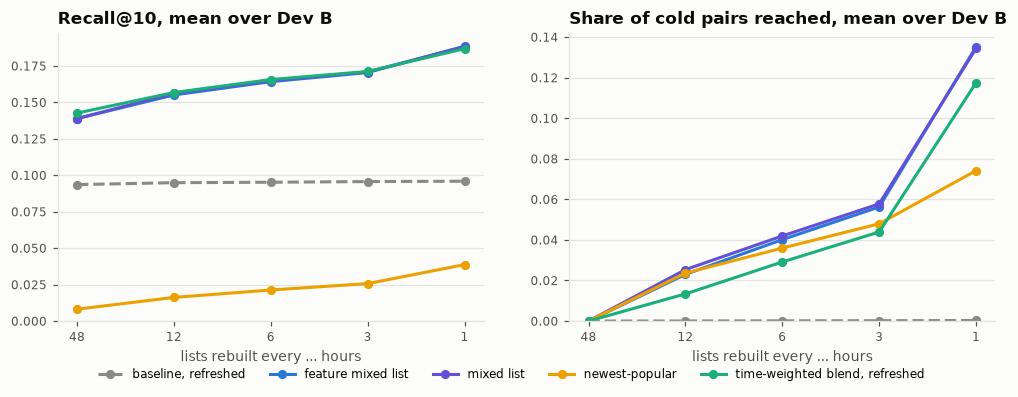

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
colours = {"baseline, refreshed": plots.BASELINE_GREY, "newest-popular": plots.colour("newest-popular"),
           "time-weighted blend, refreshed": plots.colour("time-weighted blend"), "mixed list": plots.SERIES[4],
           "feature mixed list": plots.SERIES[0]}  # fmt: skip
for ax, metric, title in [(axes[0], "recall", "Recall@10"), (axes[1], "cold_reached", "Share of cold pairs reached")]:
    for name, part in dev_b.groupby("model"):
        curve = part.groupby("refresh_hours")[metric].mean().sort_index(ascending=False)
        ax.plot([str(h) for h in curve.index], curve.to_numpy(), marker="o", color=colours[name], label=name,
                linestyle="--" if name.startswith("baseline") else "-")  # fmt: skip
    ax.set_xlabel("lists rebuilt every ... hours")
    ax.set_title(f"{title}, mean over Dev B")
    ax.set_ylim(bottom=0)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.08))
plt.show()

## 4. Paired comparison at each refresh interval

Point by point, at each refresh interval, two comparisons:

- the mixed list against the baseline refreshed in the same way (the comparison the plan asks for),
- the mixed list against the time-weighted blend alone, refreshed in the same way. This isolates what the slot
  for a new token adds.

Both for the newest-popular mixed list and for the feature-score mixed list.

In [10]:
rows = []
for hours in REFRESH:
    at = dev_b[dev_b["refresh_hours"] == hours]
    for name in ["mixed list", "feature mixed list"]:
        for reference in ["baseline, refreshed", "time-weighted blend, refreshed"]:
            d = stats.paired_differences(at[at["model"] == name], at[at["model"] == reference])
            low, high = stats.bootstrap_over_points(d)
            rows.append({"refresh_hours": hours, "model": name, "against": reference, "mean_difference": d.mean(),
                         "interval_low": low, "interval_high": high, "wins": f"{stats.sign_test(d)['wins']} of {len(d)}"})  # fmt: skip
paired = pd.DataFrame(rows)
paired.to_csv(OUT / "paired_mixed_vs_baseline_dev_b.csv", index=False)
paired

,refresh_hours,model,against,mean_difference,interval_low,interval_high,wins
0,48,mixed list,"baseline, refreshed",0.0453,0.0396,0.0511,11 of 11
1,48,mixed list,"time-weighted blend, refreshed",-0.0038,-0.0071,0.0006,2 of 11
2,48,feature mixed list,"baseline, refreshed",0.0453,0.0397,0.0512,11 of 11
3,48,feature mixed list,"time-weighted blend, refreshed",-0.0037,-0.0071,0.0007,2 of 11
4,12,mixed list,"baseline, refreshed",0.0612,0.0528,0.0703,11 of 11
5,12,mixed list,"time-weighted blend, refreshed",-0.0006,-0.0039,0.0030,4 of 11
6,12,feature mixed list,"baseline, refreshed",0.0602,0.0521,0.0691,11 of 11
7,12,feature mixed list,"time-weighted blend, refreshed",-0.0017,-0.0047,0.0019,3 of 11
8,6,mixed list,"baseline, refreshed",0.0697,0.0614,0.0779,11 of 11
9,6,mixed list,"time-weighted blend, refreshed",-0.0008,-0.0040,0.0029,5 of 11


## 5. Reading

- **New tokens are picked up very fast.** 77% of cold pairs on Dev A are traded within 1 hour of the token's first
  trade, 90% within 6 hours. A list made once a day can therefore reach almost none of them.
- **Rebuilding lists often helps a lot, but mostly not through cold tokens.** The time-weighted blend goes from
  recall 0.143 (one list per 2 days) to 0.187 (rebuilt every hour) on Dev B. The refreshed baseline barely moves
  (0.094 → 0.096). Most of the gain comes from the blend reacting to what the account did earlier in the same two
  days, not from reaching new tokens.
- **Cold pairs reached:** with hourly rebuilds the blend alone reaches 12% of cold pairs, either mixed list 13–14%;
  with 6-hourly rebuilds 3% and 4%. Most of the cold-start part stays out of reach even with hourly rebuilds.
- **The slot for a new token adds nothing to recall**, whichever way young tokens are ranked. Against the blend
  alone, refreshed in the same way, both mixed lists differ by −0.004 to +0.002 at every refresh interval, and
  every interval contains 0. On Dev A the blend alone was also slightly better than every mixed list. The slot
  reaches a few more cold pairs but costs about as many warm hits.
- **The feature score ranks young tokens almost exactly like newest-popular.** Its strongest feature by far is the
  number of accounts in the token's first day (standardized coefficient 0.36 for $A$ = 24 h, 0.77 for $A$ = 6 h),
  which is what newest-popular counts. Age matters a little (younger is better), the first hour and the launch
  currency hardly at all. On Dev B the two mixed lists are within 0.001 of each other at every interval.
- **Newest-popular alone is weak** (recall 0.008–0.039): new tokens are many and most are picked up by few accounts.
- **Against the baseline**, refreshed in the same way, both mixed lists win all 11 points at every interval, by
  +0.045 (48 h) to +0.093 (1 h). That gain belongs to the blend, not to the cold-start part.

**Answer to research question 3.** Under the main protocol 24–31% of the target is cold. Refreshed lists make up to
13–14% of that part reachable (hourly rebuilds), and the token features available in swap data add nothing beyond
counting early accounts. What helps is rebuilding the personalized lists often, for all tokens.